# Customer Segmentation Analysis — Oasis Infobyte Level 1 Task 2

## Objective and business question
Can we group identified Online Retail customers by purchase recency, invoice frequency, and spend, then use those groups to tailor customer marketing?

The analysis uses customer-level RFM. Monetary value is observed revenue in this one-year transaction extract, not a forecast of lifetime value. Results describe this dataset and do not establish causal marketing effects.

## Dataset
The supplied file is `OnlineRetail.csv` (UCI Online Retail, 2010-12-01 through 2011-12-09). The file is stored alongside this notebook. It is a Latin-1 encoded CSV. See `README.md` for source and data layout.


In [1]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

RANDOM_STATE = 42
BASE_DIR = Path.cwd()
# Let this notebook also work when launched from the repository root.
if not (BASE_DIR / 'OnlineRetail.csv').exists() and (BASE_DIR / 'DataAnalytics-L1-CustomerSegmentation' / 'OnlineRetail.csv').exists():
    BASE_DIR = BASE_DIR / 'DataAnalytics-L1-CustomerSegmentation'
DATA_PATH = BASE_DIR / 'OnlineRetail.csv'
OUTPUT_DIR = BASE_DIR / 'outputs'
OUTPUT_DIR.mkdir(exist_ok=True)
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette('colorblind')
print(f'Dataset: {DATA_PATH.resolve()}')
print(f'Outputs: {OUTPUT_DIR.resolve()}')

Dataset: C:\Users\penta\Downloads\OIBSIP\DataAnalytics-L1-CustomerSegmentation\OnlineRetail.csv
Outputs: C:\Users\penta\Downloads\OIBSIP\DataAnalytics-L1-CustomerSegmentation\outputs


## Load and inspect
`InvoiceNo` identifies invoices, `InvoiceDate` supplies purchase timing, `CustomerID` identifies the customer, and `Quantity × UnitPrice` supplies transaction-line revenue. `StockCode`, `Description`, and `Country` are descriptive fields and are not clustering inputs.


In [2]:
raw = pd.read_csv(DATA_PATH, encoding='latin1')
print('Shape:', raw.shape)
display(raw.head())
print('Columns:', raw.columns.tolist())
print('Data types before parsing:')
display(raw.dtypes.astype(str).rename('dtype').to_frame())
quality = pd.DataFrame({
    'dtype': raw.dtypes.astype(str),
    'missing': raw.isna().sum(),
    'missing_pct': (raw.isna().mean() * 100).round(2),
    'unique_non_null': raw.nunique(dropna=True),
})
display(quality)
print('Exact duplicate rows:', int(raw.duplicated().sum()))
print('Invoice numbers beginning with C:', int(raw['InvoiceNo'].astype(str).str.startswith('C').sum()))
print('Negative quantity (return/credit lines):', int(raw['Quantity'].lt(0).sum()))
print('Zero quantity:', int(raw['Quantity'].eq(0).sum()))
print('Zero unit price:', int(raw['UnitPrice'].eq(0).sum()))
print('Negative unit price:', int(raw['UnitPrice'].lt(0).sum()))
print('Customer IDs present:', int(raw['CustomerID'].notna().sum()), '| unique IDs:', int(raw['CustomerID'].nunique()))

Shape: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850.0,United Kingdom


Columns: ['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']
Data types before parsing:


,dtype
InvoiceNo,str
StockCode,str
Description,str
Quantity,int64
InvoiceDate,str
UnitPrice,float64
CustomerID,float64
Country,str


,dtype,missing,missing_pct,unique_non_null
InvoiceNo,str,0,0.00,25900
StockCode,str,0,0.00,4070
Description,str,1454,0.27,4223
Quantity,int64,0,0.00,722
InvoiceDate,str,0,0.00,23260
UnitPrice,float64,0,0.00,1630
CustomerID,float64,135080,24.93,4372
Country,str,0,0.00,38


Exact duplicate rows: 5268
Invoice numbers beginning with C: 9288
Negative quantity (return/credit lines): 10624
Zero quantity: 0
Zero unit price: 2515
Negative unit price: 2
Customer IDs present: 406829 | unique IDs: 4372


## Cleaning decisions

- Remove exact duplicate transaction rows so repeated records do not inflate revenue or invoice counts.
- Parse invoice timestamps using the source's month/day/year hour:minute format. Invalid dates are excluded and counted.
- Exclude cancellation invoices (invoice numbers beginning with `C`), because they represent cancelled transactions. Exclude nonpositive quantity and nonpositive unit price lines because they cannot represent valid positive purchases; this also excludes return/credit lines recorded with negative quantities. The raw quality counts are reported above.
- Exclude rows without `CustomerID` from customer segmentation because they cannot be assigned to a customer. Keep `Description` missingness from preventing analysis since it is not an RFM field.
- Do not impute transaction amounts or customer IDs. The resulting segmentation therefore represents identified customers with valid positive purchases only.


In [3]:
transactions = raw.drop_duplicates().copy()
transactions['InvoiceDate'] = pd.to_datetime(
    transactions['InvoiceDate'], format='%m/%d/%Y %H:%M', errors='coerce'
)
invalid_date_rows = int(transactions['InvoiceDate'].isna().sum())
cancel_mask = transactions['InvoiceNo'].astype(str).str.startswith('C')
return_or_invalid_qty_mask = transactions['Quantity'].le(0)
invalid_price_mask = transactions['UnitPrice'].le(0)
missing_customer_mask = transactions['CustomerID'].isna()

clean = transactions.loc[
    ~cancel_mask
    & ~return_or_invalid_qty_mask
    & ~invalid_price_mask
    & ~missing_customer_mask
    & transactions['InvoiceDate'].notna()
].copy()
clean['CustomerID'] = clean['CustomerID'].astype('int64')
clean['Revenue'] = clean['Quantity'] * clean['UnitPrice']
print(f'Rows after exact duplicate removal: {len(transactions):,}')
print(f'Invalid dates after parsing: {invalid_date_rows:,}')
print(f'Rows eligible for RFM: {len(clean):,}')
print(f'Identified customers eligible for RFM: {clean.CustomerID.nunique():,}')
print(f'Valid purchase period: {clean.InvoiceDate.min()} to {clean.InvoiceDate.max()}')
print('Remaining missing values in analysis fields:', clean[['InvoiceNo','InvoiceDate','Quantity','UnitPrice','CustomerID','Revenue']].isna().sum().to_dict())
print('Remaining nonpositive quantity or price:', int((clean['Quantity'].le(0) | clean['UnitPrice'].le(0)).sum()))

Rows after exact duplicate removal: 536,641
Invalid dates after parsing: 0
Rows eligible for RFM: 392,692
Identified customers eligible for RFM: 4,338
Valid purchase period: 2010-12-01 08:26:00 to 2011-12-09 12:50:00
Remaining missing values in analysis fields: {'InvoiceNo': 0, 'InvoiceDate': 0, 'Quantity': 0, 'UnitPrice': 0, 'CustomerID': 0, 'Revenue': 0}
Remaining nonpositive quantity or price: 0


## Construct customer-level RFM features

- **Recency:** days between a common reference date (one day after the final valid transaction date) and the customer's last purchase. Lower is more recent.
- **Frequency:** distinct valid purchase invoices in the observed period.
- **Monetary:** sum of positive line revenue (`Quantity × UnitPrice`) in the observed period.

Frequency counts invoices rather than lines, and monetary is historical observed spend, not customer lifetime value. `AveragePurchaseValue` is also included in exported descriptive results as Monetary divided by Frequency. RFM are the three clustering features.


In [4]:
reference_date = clean['InvoiceDate'].max().normalize() + pd.Timedelta(days=1)
rfm = clean.groupby('CustomerID').agg(
    LastPurchase=('InvoiceDate', 'max'),
    Frequency=('InvoiceNo', 'nunique'),
    Monetary=('Revenue', 'sum'),
)
rfm['Recency'] = (reference_date - rfm['LastPurchase'].dt.normalize()).dt.days
rfm['AveragePurchaseValue'] = rfm['Monetary'] / rfm['Frequency']
rfm = rfm[['Recency', 'Frequency', 'Monetary', 'AveragePurchaseValue']].reset_index()
assert rfm[['Recency','Frequency','Monetary']].notna().all().all()
assert (rfm[['Recency','Frequency','Monetary']] >= 0).all().all()
display(rfm.describe().T.round(2))
rfm.to_csv(OUTPUT_DIR / 'customer_rfm.csv', index=False)

,count,mean,std,min,25%,50%,75%,max
CustomerID,4338.0,15300.41,1721.81,12346.00,13813.25,15299.50,16778.75,18287.00
Recency,4338.0,93.06,100.01,1.00,18.00,51.00,142.75,374.00
Frequency,4338.0,4.27,7.70,1.00,1.00,2.00,5.00,209.00
Monetary,4338.0,2048.69,8985.23,3.75,306.48,668.57,1660.60,280206.02
AveragePurchaseValue,4338.0,417.65,1796.51,3.45,177.87,291.94,428.28,84236.25


## Feature preparation and Elbow Method
RFM is strongly right-skewed, especially Monetary and Frequency. Apply `log1p` to the three nonnegative features before standardization, then fit K-Means on the standardized values. This retains all customers while reducing the influence of extreme values. Candidate K values are 2–8; inertia alone is a heuristic, so the chosen K also balances a visible diminishing-return region with profiles that can be interpreted and acted on.


,k,inertia
0,2,6476.5
1,3,4858.2
2,4,3925.4
3,5,3269.3
4,6,2841.4
5,7,2533.0
6,8,2325.1


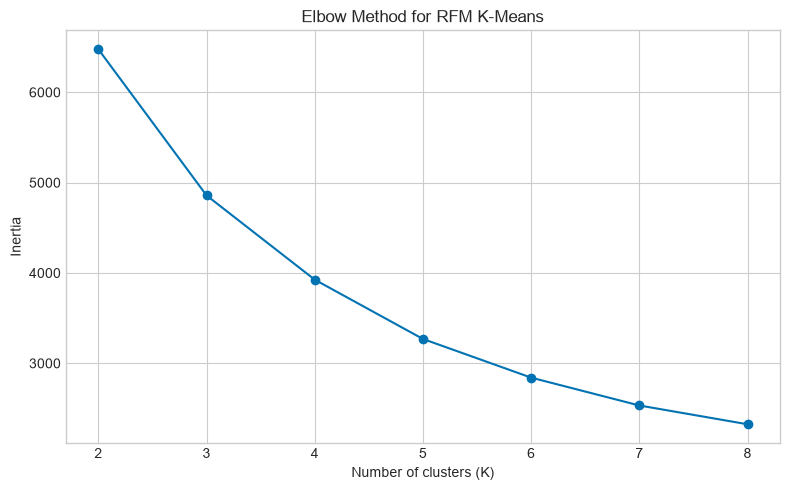

In [5]:
FEATURES = ['Recency', 'Frequency', 'Monetary']
X_log = np.log1p(rfm[FEATURES])
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_log)
k_values = range(2, 9)
inertias = []
for k in k_values:
    model = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    model.fit(X_scaled)
    inertias.append(model.inertia_)
elbow = pd.DataFrame({'k': list(k_values), 'inertia': inertias})
display(elbow.round(1))
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(elbow['k'], elbow['inertia'], marker='o')
ax.set(title='Elbow Method for RFM K-Means', xlabel='Number of clusters (K)', ylabel='Inertia')
ax.set_xticks(list(k_values))
fig.tight_layout()
fig.savefig(OUTPUT_DIR / 'elbow_method.png', dpi=160, bbox_inches='tight')
plt.show()
# K=4 is used for the diminishing-return region and clear, actionable profiles.
SELECTED_K = 4


## Fit K-Means and profile segments
K-Means uses a fixed random seed and `n_init=10` for repeatable initialization. Cluster numbers are arbitrary identifiers, not an ordinal score. The profiles below are reported in original units so that they are meaningful to a business reader.


In [6]:
kmeans = KMeans(n_clusters=SELECTED_K, random_state=RANDOM_STATE, n_init=10)
rfm['Cluster'] = kmeans.fit_predict(X_scaled)
cluster_profile = rfm.groupby('Cluster').agg(
    Customers=('CustomerID', 'size'),
    Recency_days=('Recency', 'mean'),
    Frequency_invoices=('Frequency', 'mean'),
    Monetary_observed=('Monetary', 'mean'),
    Average_purchase_value=('AveragePurchaseValue', 'mean'),
).round(2)
cluster_profile['Customer_share_pct'] = (cluster_profile['Customers'] / len(rfm) * 100).round(2)
display(cluster_profile)
cluster_profile.to_csv(OUTPUT_DIR / 'cluster_profiles.csv')
rfm.to_csv(OUTPUT_DIR / 'customer_segments.csv', index=False)
print('Total customers:', len(rfm))
print('RFM reference date:', reference_date.date())

,Customers,Recency_days,Frequency_invoices,Monetary_observed,Average_purchase_value,Customer_share_pct
Cluster,,,,,,
0,897,22.79,1.92,486.06,281.49,20.68
1,1174,65.29,4.19,1822.98,566.38,27.06
2,1549,192.27,1.35,360.55,290.76,35.71
3,718,12.21,13.64,8011.89,618.28,16.55


Total customers: 4338
RFM reference date: 2011-12-10


## Visualize cluster profiles
The scatterplots use original RFM units and logarithmic axes for Frequency and Monetary to make the long-tailed distributions easier to inspect. They show two distinct feature combinations. The color legend refers to K-Means cluster identifiers.


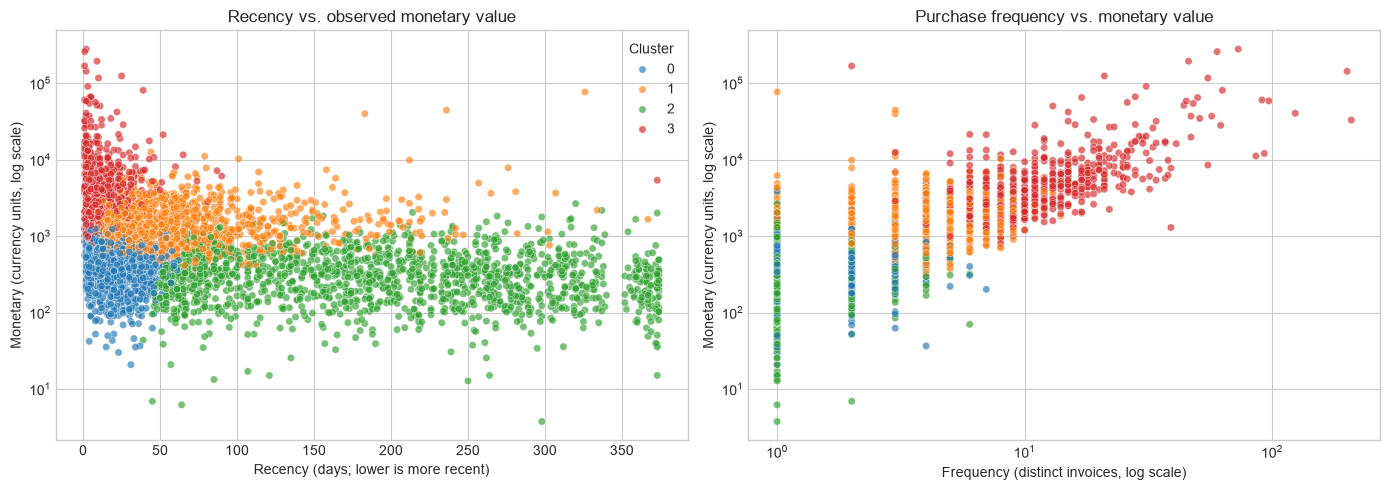

In [7]:
plot_data = rfm.copy()
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.scatterplot(data=plot_data, x='Recency', y='Monetary', hue='Cluster', palette='tab10', alpha=0.65, s=28, ax=axes[0])
axes[0].set_yscale('log')
axes[0].set(title='Recency vs. observed monetary value', xlabel='Recency (days; lower is more recent)', ylabel='Monetary (currency units, log scale)')
sns.scatterplot(data=plot_data, x='Frequency', y='Monetary', hue='Cluster', palette='tab10', alpha=0.65, s=28, ax=axes[1], legend=False)
axes[1].set_xscale('log')
axes[1].set_yscale('log')
axes[1].set(title='Purchase frequency vs. monetary value', xlabel='Frequency (distinct invoices, log scale)', ylabel='Monetary (currency units, log scale)')
fig.tight_layout()
fig.savefig(OUTPUT_DIR / 'cluster_scatterplots.png', dpi=160, bbox_inches='tight')
plt.show()

## Customer counts and marketing actions
The count chart communicates segment sizes. The data-driven descriptions and suggested actions below are generated from each cluster's actual mean Recency, Frequency, and Monetary values. These are hypotheses for targeted campaigns; campaign testing would be needed to measure impact.


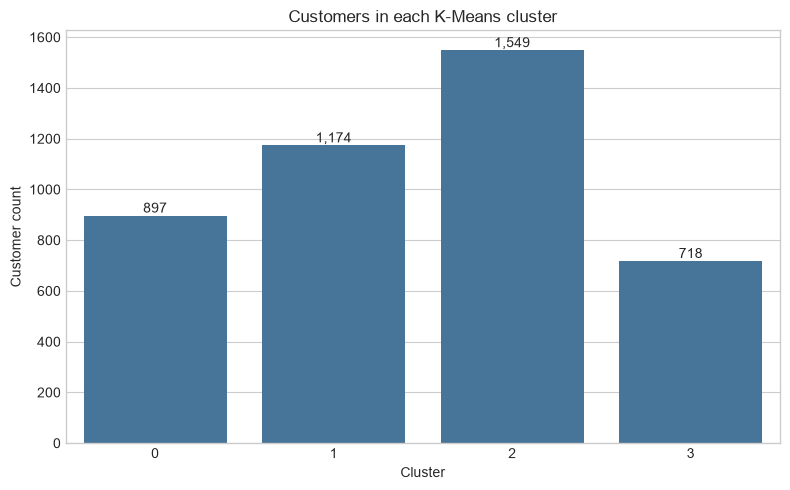

,Customers,Recency_days,Frequency_invoices,Monetary_observed,Average_purchase_value,Customer_share_pct,Profile,Marketing_action
Cluster,,,,,,,,
0,897,22.79,1.92,486.06,281.49,20.68,Lower-spend or occasional customers,Use low-cost segmented recommendations and onb...
1,1174,65.29,4.19,1822.98,566.38,27.06,Frequent customers with repeat-purchase potential,Use replenishment reminders and bundles; test ...
2,1549,192.27,1.35,360.55,290.76,35.71,"Less recent, infrequent customers",Run a win-back message with a relevant product...
3,718,12.21,13.64,8011.89,618.28,16.55,"Recent, frequent, high-spend customers","Reward loyalty with early access, VIP service,..."


In [8]:
fig, ax = plt.subplots(figsize=(8, 5))
counts = rfm['Cluster'].value_counts().sort_index()
sns.barplot(x=counts.index.astype(str), y=counts.values, color='#3977a8', ax=ax)
ax.set(title='Customers in each K-Means cluster', xlabel='Cluster', ylabel='Customer count')
for i, value in enumerate(counts.values):
    ax.text(i, value, f'{value:,}', ha='center', va='bottom')
fig.tight_layout()
fig.savefig(OUTPUT_DIR / 'cluster_customer_counts.png', dpi=160, bbox_inches='tight')
plt.show()

# Relative thresholds use this dataset's actual cluster averages.
med_r = cluster_profile['Recency_days'].median()
med_f = cluster_profile['Frequency_invoices'].median()
med_m = cluster_profile['Monetary_observed'].median()
actions = []
for cluster, row in cluster_profile.iterrows():
    recent = row['Recency_days'] <= med_r
    frequent = row['Frequency_invoices'] >= med_f
    high_value = row['Monetary_observed'] >= med_m
    if recent and frequent and high_value:
        description = 'Recent, frequent, high-spend customers'
        action = 'Reward loyalty with early access, VIP service, and carefully tested cross-sell offers.'
    elif not recent and not frequent:
        description = 'Less recent, infrequent customers'
        action = 'Run a win-back message with a relevant product reminder; cap incentives and monitor response.'
    elif frequent:
        description = 'Frequent customers with repeat-purchase potential'
        action = 'Use replenishment reminders and bundles; test ways to grow basket value without discounting every order.'
    elif recent and high_value:
        description = 'Recent customers with above-median spend'
        action = 'Encourage a second purchase through complementary recommendations and a short follow-up.'
    else:
        description = 'Lower-spend or occasional customers'
        action = 'Use low-cost segmented recommendations and onboarding; reserve broad discounts for tested offers.'
    actions.append({'Cluster': cluster, 'Profile': description, 'Marketing_action': action})
recommendations = pd.DataFrame(actions).set_index('Cluster')
cluster_profile = cluster_profile.join(recommendations)
display(cluster_profile)
cluster_profile.to_csv(OUTPUT_DIR / 'cluster_profiles.csv')


## Findings and limitations

Use the profile table and plots above as the results. The segment definitions compare each segment's RFM means with the median segment mean, so they are relative to this particular dataset and selected K. Monetary values use the source's nominal `UnitPrice` without a documented currency symbol; interpret them as source currency units.

The extract spans about one year and ends in December 2011. Frequency and Monetary therefore reflect only the observed window and are not full customer lifetime value. Excluding unidentified customers and returns/cancellations is appropriate for positive-purchase RFM but means those activities are not represented in the customer segments. K-Means is sensitive to feature choices and the selected K; profile segments before activating a campaign.


## References

- UCI Machine Learning Repository, [Online Retail](https://archive.ics.uci.edu/dataset/352/online+retail). The supplied `OnlineRetail.csv` is the dataset used here.
- scikit-learn documentation: [StandardScaler](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html), [KMeans](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.KMeans.html).
